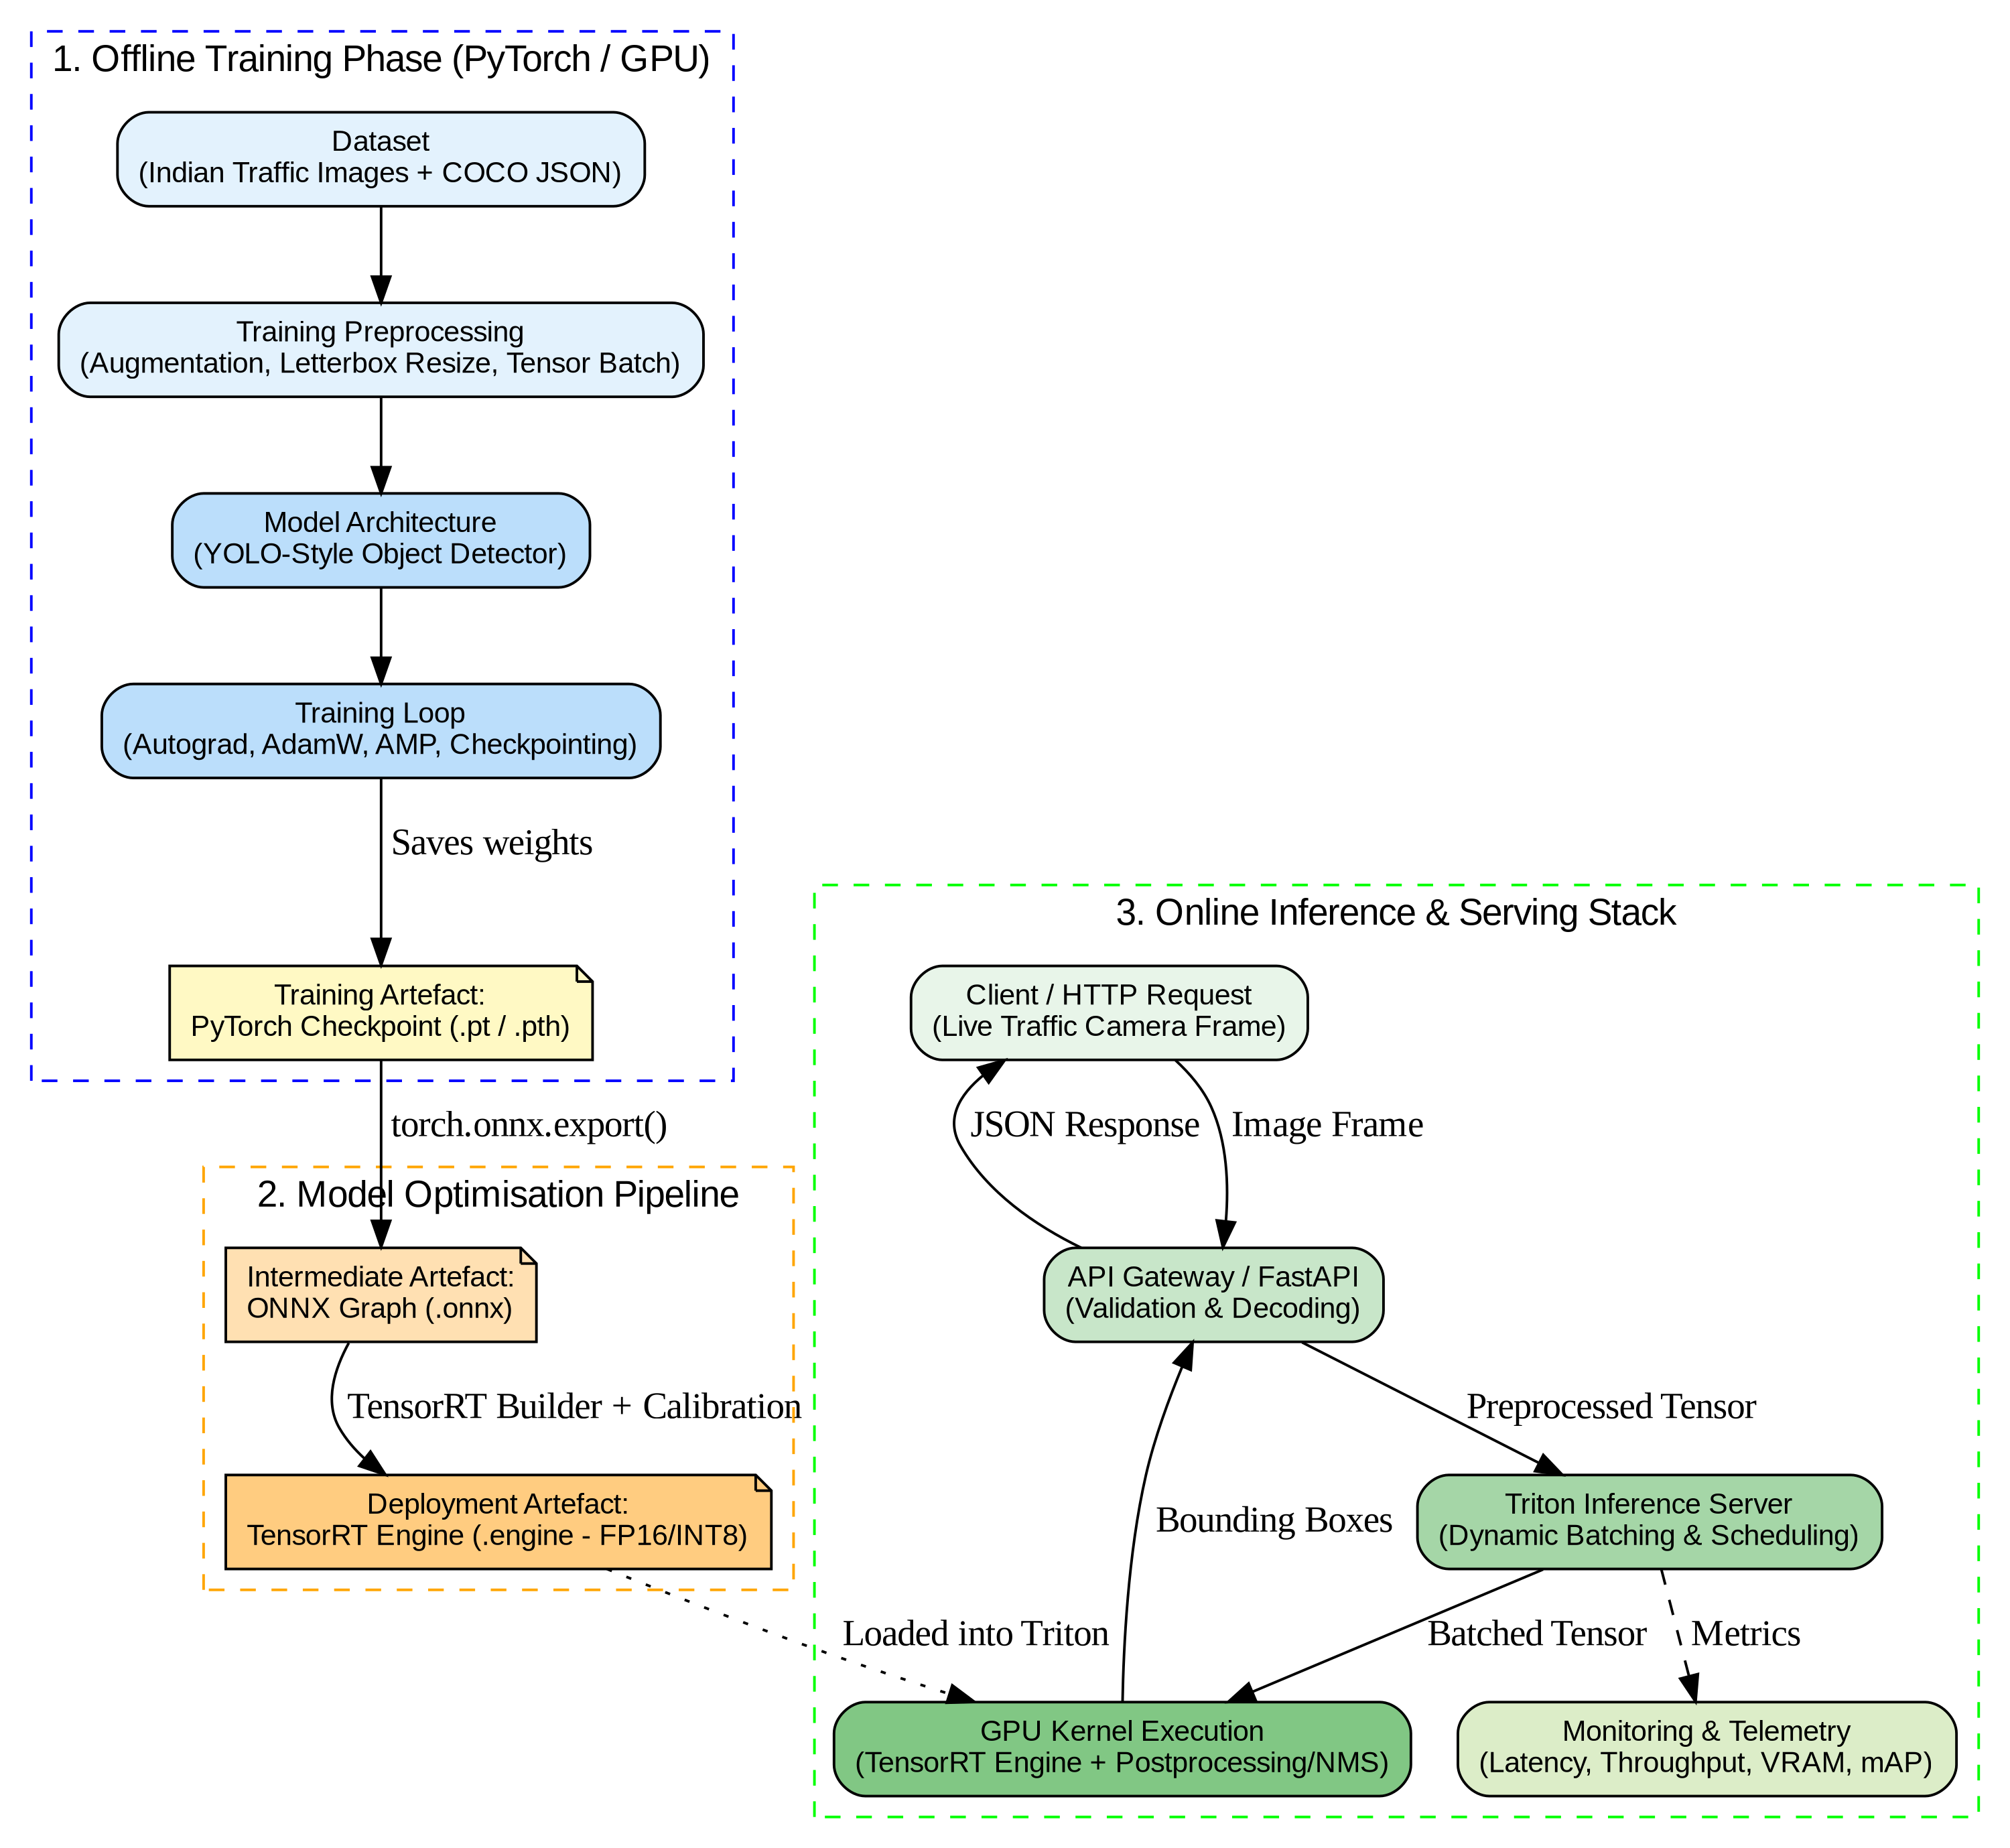

In [ ]:
from graphviz import Digraph
from IPython.display import Image, display

dot = Digraph(comment='VisionPort Deep Learning Lifecycle', format='png')
dot.attr(rankdir='TB', size='10,12', dpi='300', fontname='Helvetica')
dot.attr('node', shape='box', style='rounded,filled', fontname='Helvetica', fontsize='11')

# Phase 1: Data & Training
with dot.subgraph(name='cluster_0') as c:
    c.attr(label='1. Offline Training Phase (PyTorch / GPU)', style='dashed', color='blue')
    c.node('D', 'Dataset\n(Indian Traffic Images + COCO JSON)', fillcolor='#E3F2FD')
    c.node('P1', 'Training Preprocessing\n(Augmentation, Letterbox Resize, Tensor Batch)', fillcolor='#E3F2FD')
    c.node('M', 'Model Architecture\n(YOLO-Style Object Detector)', fillcolor='#BBDEFB')
    c.node('T', 'Training Loop\n(Autograd, AdamW, AMP, Checkpointing)', fillcolor='#BBDEFB')
    c.node('CKPT', 'Training Artefact:\nPyTorch Checkpoint (.pt / .pth)', shape='note', fillcolor='#FFF9C4')

# Phase 2: Optimisation & Compilation
with dot.subgraph(name='cluster_1') as c:
    c.attr(label='2. Model Optimisation Pipeline', style='dashed', color='orange')
    c.node('ONNX', 'Intermediate Artefact:\nONNX Graph (.onnx)', shape='note', fillcolor='#FFE0B2')
    c.node('TRT', 'Deployment Artefact:\nTensorRT Engine (.engine - FP16/INT8)', shape='note', fillcolor='#FFCC80')

# Phase 3: Production Serving & Monitoring
with dot.subgraph(name='cluster_2') as c:
    c.attr(label='3. Online Inference & Serving Stack', style='dashed', color='green')
    c.node('CLI', 'Client / HTTP Request\n(Live Traffic Camera Frame)', fillcolor='#E8F5E9')
    c.node('API', 'API Gateway / FastAPI\n(Validation & Decoding)', fillcolor='#C8E6C9')
    c.node('TRI', 'Triton Inference Server\n(Dynamic Batching & Scheduling)', fillcolor='#A5D6A7')
    c.node('GPU', 'GPU Kernel Execution\n(TensorRT Engine + Postprocessing/NMS)', fillcolor='#81C784')
    c.node('MON', 'Monitoring & Telemetry\n(Latency, Throughput, VRAM, mAP)', fillcolor='#DCEDC8')

# Edges
dot.edge('D', 'P1')
dot.edge('P1', 'M')
dot.edge('M', 'T')
dot.edge('T', 'CKPT', label=' Saves weights')
dot.edge('CKPT', 'ONNX', label=' torch.onnx.export()')
dot.edge('ONNX', 'TRT', label=' TensorRT Builder + Calibration')
dot.edge('CLI', 'API', label=' Image Frame')
dot.edge('API', 'TRI', label=' Preprocessed Tensor')
dot.edge('TRI', 'GPU', label=' Batched Tensor')
dot.edge('TRT', 'GPU', style='dotted', label=' Loaded into Triton')
dot.edge('GPU', 'API', label=' Bounding Boxes')
dot.edge('API', 'CLI', label=' JSON Response')
dot.edge('TRI', 'MON', style='dashed', label=' Metrics')

dot.render('visionport_lifecycle_map', cleanup=True)
display(Image('visionport_lifecycle_map.png'))